<a href="https://colab.research.google.com/github/rehanaga86-tech/RCA-Activity-1/blob/main/RCA_Activity_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(42)

In [14]:
df = pd.read_csv("housing.csv")
print("Raw shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df = df[df["median_house_value"] < 500001.0].dropna(subset=["total_bedrooms"]).copy()
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_household"] = df["total_bedrooms"] / df["households"]
df["persons_per_household"] = df["population"] / df["households"]

features = [
    "median_income",
    "housing_median_age",
    "rooms_per_household",
    "bedrooms_per_household",
    "persons_per_household"
]
target = "median_house_value"

for col in ["rooms_per_household", "bedrooms_per_household", "persons_per_household"]:
    low = df[col].quantile(0.005)
    high = df[col].quantile(0.995)
    df = df[(df[col] >= low) & (df[col] <= high)]

df = df[features + [target]].reset_index(drop=True)
print("\nClean shape:", df.shape)
print(df.describe().round(2))

Raw shape: (20640, 10)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  

Missing values:
 longitude               0
latitude

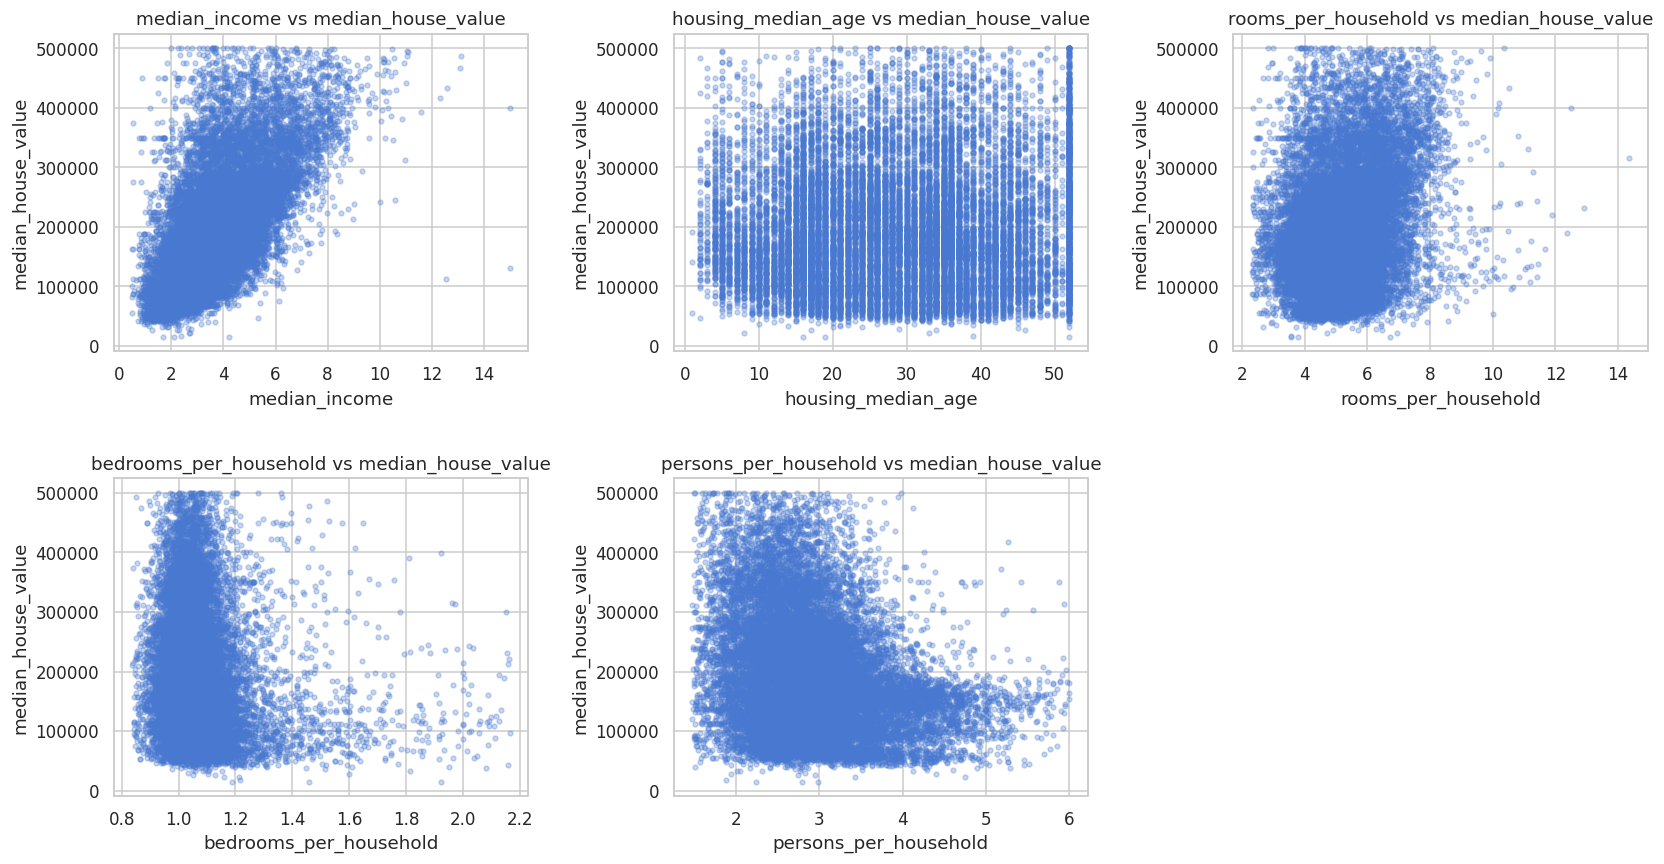

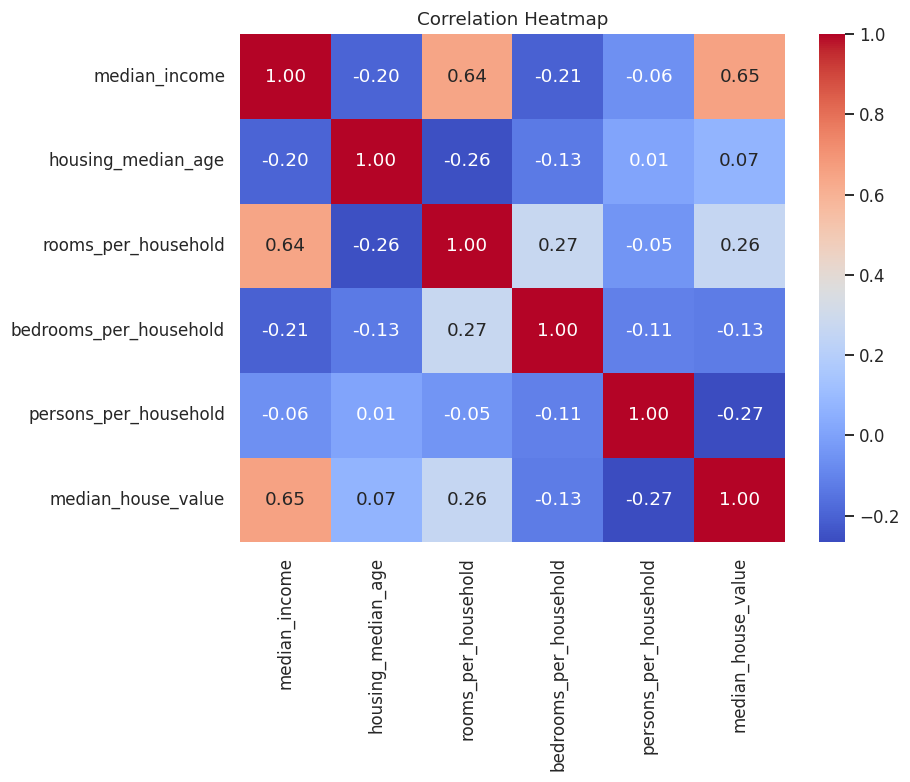

In [25]:
n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows))
plt.subplots_adjust(wspace=0.35, hspace=0.4)
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].scatter(df[col], df[target], alpha=0.3, s=10)
    axes[i].set_title(f"{col} vs {target}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target)

for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [16]:
sample = df.loc[[0, 10, 20, 30, 40, 50], ["median_income", "housing_median_age", "median_house_value"]].round(2)
print("Sample data:\n", sample)

X_small = np.column_stack([np.ones(len(sample)), sample["median_income"], sample["housing_median_age"]])
y_small = sample["median_house_value"].values

XTX = X_small.T @ X_small
XTy = X_small.T @ y_small
b_hand = np.linalg.solve(XTX, XTy)

print("\nX^T X:\n", np.round(XTX, 2))
print("\nX^T y:\n", np.round(XTy, 2))
print("\nHand coefficients [b0, b1, b2]:", np.round(b_hand, 4))

lr_small = LinearRegression().fit(sample[["median_income", "housing_median_age"]], sample["median_house_value"])
print("Library intercept:", round(lr_small.intercept_, 4))
print("Library coefficients:", np.round(lr_small.coef_, 4))

pred_row0 = b_hand[0] + b_hand[1] * sample.loc[0, "median_income"] + b_hand[2] * sample.loc[0, "housing_median_age"]
res_row0 = sample.loc[0, "median_house_value"] - pred_row0
print(f"\nRow 0 -> Actual: {sample.loc[0, 'median_house_value']}, Predicted: {pred_row0:.2f}, Residual: {res_row0:.2f}")

Sample data:
     median_income  housing_median_age  median_house_value
0            8.33                41.0            452600.0
10           3.20                52.0            281500.0
20           1.36                40.0            147500.0
30           1.93                49.0            122300.0
40           2.10                52.0            155400.0
50           1.50                43.0             93800.0

X^T X:
 [[6.0000e+00 1.8420e+01 2.7700e+02]
 [1.8420e+01 9.1860e+01 8.3060e+02]
 [2.7700e+02 8.3060e+02 1.2939e+04]]

X^T y:
 [ 1253100.  5574637. 57201500.]

Hand coefficients [b0, b1, b2]: [-50383.6437  50197.7678   2277.1082]
Library intercept: -50383.6437
Library coefficients: [50197.7678  2277.1082]

Row 0 -> Actual: 452600.0, Predicted: 461125.20, Residual: -8525.20


In [17]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", len(X_train), "| Test size:", len(X_test))

single_model = LinearRegression().fit(X_train[["median_income"]], y_train)
print("\nSingle-feature model (median_income):")
print("Intercept:", round(single_model.intercept_, 2), "| Coef:", round(single_model.coef_[0], 2))

multi_model = LinearRegression().fit(X_train, y_train)
print("\nMultiple regression model:")
print("Intercept:", round(multi_model.intercept_, 2))
for name, coef in zip(features, multi_model.coef_):
    print(f"  {name}: {coef:.2f}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
scaled_model = LinearRegression().fit(X_train_scaled, y_train)
print("\nStandardized coefficients:")
for name, coef in zip(features, scaled_model.coef_):
    print(f"  {name}: {coef:.2f}")

Train size: 15114 | Test size: 3779

Single-feature model (median_income):
Intercept: 39879.34 | Coef: 41370.67

Multiple regression model:
Intercept: 31795.52
  median_income: 58652.87
  housing_median_age: 1457.73
  rooms_per_household: -28585.21
  bedrooms_per_household: 127740.10
  persons_per_household: -28349.15

Standardized coefficients:
  median_income: 91755.18
  housing_median_age: 18220.19
  rooms_per_household: -33471.45
  bedrooms_per_household: 15528.86
  persons_per_household: -20070.61


In [18]:
pred_mean = np.full(len(y_test), y_train.mean())
pred_single = single_model.predict(X_test[["median_income"]])
pred_multi = multi_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values[:10].round(0),
    "Single_Pred": pred_single[:10].round(0),
    "Multi_Pred": pred_multi[:10].round(0),
    "Error": (y_test.values[:10] - pred_multi[:10]).round(0)
})
print("Sample test predictions:\n", comparison)

def show_metrics(label, y_true, y_pred, p):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    print(f"{label:22s} | MAE: {mae:8.2f} | MSE: {mse:13.2f} | RMSE: {rmse:8.2f} | R2: {r2:.4f} | Adj R2: {adj_r2:.4f}")

print("\nTest Set Evaluation:")
show_metrics("Mean Baseline", y_test, pred_mean, 0)
show_metrics("Single Feature", y_test, pred_single, 1)
show_metrics("Multiple Features", y_test, pred_multi, len(features))

Sample test predictions:
      Actual  Single_Pred  Multi_Pred     Error
0   87500.0      75698.0     70178.0   17322.0
1  105400.0      97914.0    -10916.0  116316.0
2  110700.0     156698.0    142364.0  -31664.0
3   14999.0     213355.0    323982.0 -308983.0
4  165300.0     146003.0    168249.0   -2949.0
5  191400.0     225092.0    191417.0     -17.0
6   91200.0     165779.0    153934.0  -62734.0
7  118300.0     129968.0    129556.0  -11256.0
8  160400.0     127581.0    180883.0  -20483.0
9  118800.0      82284.0    122734.0   -3934.0

Test Set Evaluation:
Mean Baseline          | MAE: 78555.18 | MSE: 9549795641.00 | RMSE: 97723.06 | R2: -0.0000 | Adj R2: -0.0000
Single Feature         | MAE: 57331.20 | MSE: 5861540356.91 | RMSE: 76560.70 | R2: 0.3862 | Adj R2: 0.3861
Multiple Features      | MAE: 48863.69 | MSE: 4337643714.85 | RMSE: 65860.79 | R2: 0.5458 | Adj R2: 0.5452


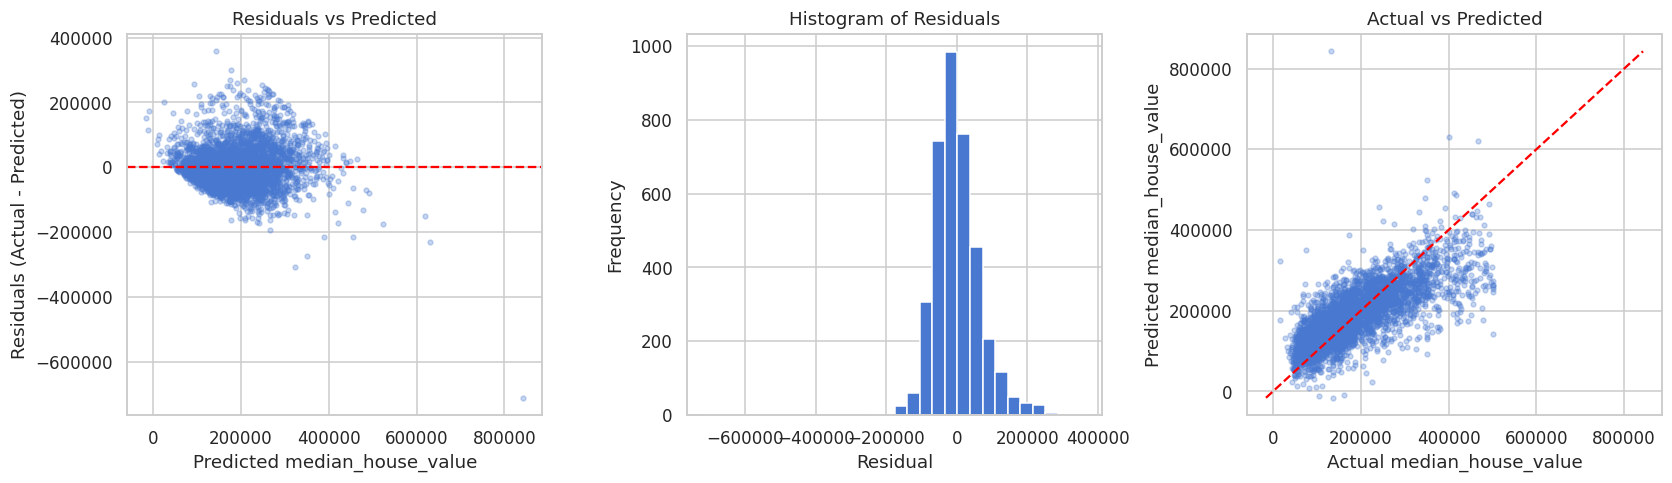


VIF scores:
  median_income: 2.40
  housing_median_age: 1.09
  rooms_per_household: 2.47
  bedrooms_per_household: 1.54
  persons_per_household: 1.03


In [24]:
residuals = y_test.values - pred_multi

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
plt.subplots_adjust(wspace=0.35)

axes[0].scatter(pred_multi, residuals, alpha=0.3, s=10)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted")
axes[0].set_xlabel("Predicted median_house_value")
axes[0].set_ylabel("Residuals (Actual - Predicted)")

axes[1].hist(residuals, bins=30)
axes[1].set_title("Histogram of Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

axes[2].scatter(y_test, pred_multi, alpha=0.3, s=10)
line_vals = [min(y_test.min(), pred_multi.min()), max(y_test.max(), pred_multi.max())]
axes[2].plot(line_vals, line_vals, color="red", linestyle="--")
axes[2].set_title("Actual vs Predicted")
axes[2].set_xlabel("Actual median_house_value")
axes[2].set_ylabel("Predicted median_house_value")

plt.show()

X_vif = np.column_stack([np.ones(len(X_train)), X_train.values])
print("\nVIF scores:")
for i, name in enumerate(features):
    vif_val = variance_inflation_factor(X_vif, i + 1)
    print(f"  {name}: {vif_val:.2f}")

In [20]:
new_data = pd.DataFrame({
    "median_income": [4.5],
    "housing_median_age": [30.0],
    "rooms_per_household": [5.4],
    "bedrooms_per_household": [1.08],
    "persons_per_household": [2.8]
})

new_pred = multi_model.predict(new_data)[0]
print(f"Predicted house value for new example: ${new_pred:,.2f}")

Predicted house value for new example: $243,686.78
